Tache C1.1 : Trouvez le nom du GPU attribue a votre session, sa temperature actuelle et sa VRAM totale. (3 pts)

In [2]:
!nvidia-smi --query-gpu=name,memory.total,temperature.gpu --format=csv,noheader,nounits

Tesla T4, 15360, 41


Tache C1.2 : Affichez la version de Python, la version de PyTorch et verifiez si CUDA est disponible. (3 pts)

In [3]:
import sys
import torch

print(f"Python : {sys.version}")
print(f"PyTorch : {torch.__version__}")
print(f"CUDA disponible : {torch.cuda.is_available()}")

Python : 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch : 2.11.0+cu128
CUDA disponible : True


C2 - Simulation de Thermal Throttling (8 points)

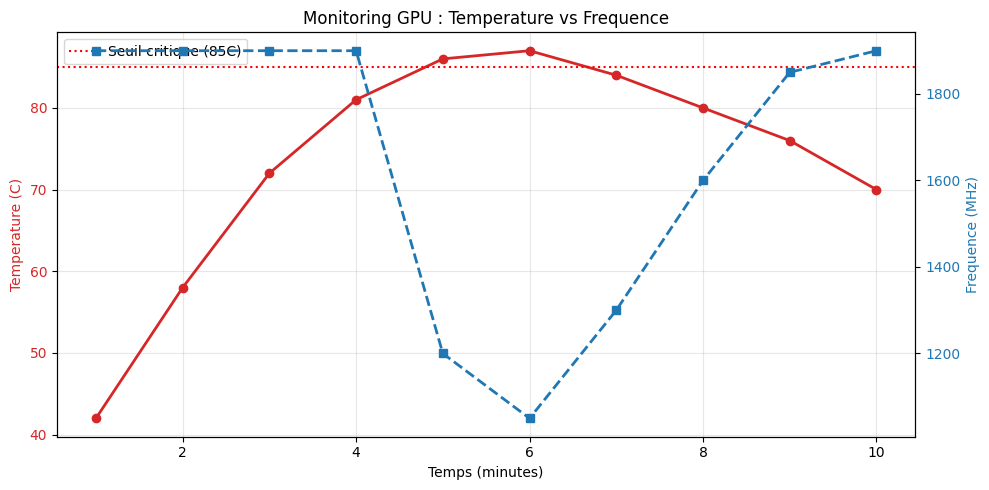

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Donnees simulees de monitoring GPU sur 10 minutes
data = {
    'temps_min': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'gpu_temp_c': [42, 58, 72, 81, 86, 87, 84, 80, 76, 70],
    'gpu_clock_mhz': [1900, 1900, 1900, 1900, 1200, 1050, 1300, 1600, 1850, 1900]
}

df = pd.DataFrame(data)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlabel('Temps (minutes)')
ax1.set_ylabel('Temperature (C)', color='tab:red')
ax1.plot(df['temps_min'], df['gpu_temp_c'], color='tab:red', marker='o', linewidth=2)
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.axhline(y=85, color='red', linestyle=':', label='Seuil critique (85C)')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.set_ylabel('Frequence (MHz)', color='tab:blue')
ax2.plot(df['temps_min'], df['gpu_clock_mhz'], color='tab:blue', linestyle='--', marker='s', linewidth=2)
ax2.tick_params(axis='y', labelcolor='tab:blue')

plt.title('Monitoring GPU : Temperature vs Frequence')
fig.tight_layout()
plt.show()


C3 - Script Watchdog (6 points)

In [6]:
def check_health(temp, gpu_load, ram_pct):
    """
    Verifie l'etat de sante d'un serveur IA.
    Regles :
    - Temperature > 85 degres C  -->  'ALERTE: Surchauffe critique'
    - GPU load < 10% alors que le serveur est cense calculer  -->  'ALERTE: Processus gele'
    - RAM > 90%  -->  'ALERTE: Memoire saturee'
    - Sinon  -->  'Systeme sain'
    """
    if temp > 85:
        return 'ALERTE: Surchauffe critique'
    elif gpu_load < 10:
        return 'ALERTE: Processus gele'
    elif ram_pct > 90:
        return 'ALERTE: Memoire saturee'
    else:
        return 'Systeme sain'

# Tests a executer :
print(check_health(88, 95, 70))   # Attendu : ALERTE: Surchauffe critique
print(check_health(65, 3, 50))    # Attendu : ALERTE: Processus gele
print(check_health(70, 80, 95))   # Attendu : ALERTE: Memoire saturee
print(check_health(60, 80, 50))   # Attendu : Systeme sain

ALERTE: Surchauffe critique
ALERTE: Processus gele
ALERTE: Memoire saturee
Systeme sain


D1 - Classification Scikit-learn avec monitoring (12 points)


In [7]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, test_size=0.3, random_state=42)

print(f'Features : {cancer.data.shape[1]}')
print(f'Classes : {list(cancer.target_names)}')
print(f'Train : {len(X_train)} | Test : {len(X_test)}')


Features : 30
Classes : [np.str_('malignant'), np.str_('benign')]
Train : 398 | Test : 171


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

# Completez les 3 lignes manquantes :
model = RandomForestClassifier(n_estimators=100, random_state=42)  # Creer le modele (100 arbres, random_state=42)
model.fit(X_train, y_train)          # Entrainer le modele
predictions = model.predict(X_test)  # Predire sur X_test

acc = accuracy_score(y_test, predictions)
print(f'Precision : {acc:.2%}')
print(classification_report(y_test, predictions, target_names=cancer.target_names))

Precision : 97.08%
              precision    recall  f1-score   support

   malignant       0.98      0.94      0.96        63
      benign       0.96      0.99      0.98       108

    accuracy                           0.97       171
   macro avg       0.97      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



In [10]:
import time

# Mesurer le temps d'entrainement
start = time.time()
model2 = RandomForestClassifier(n_estimators=1000, random_state=42)  # 1000 arbres
model2.fit(X_train, y_train)
training_time = time.time() - start

print(f'Temps avec 1000 arbres : {training_time:.3f} secondes')

# Verifier : ce modele utilise-t-il le GPU ?
print(f'GPU utilise par Scikit-learn : Non (CPU uniquement)')


Temps avec 1000 arbres : 4.466 secondes
GPU utilise par Scikit-learn : Non (CPU uniquement)


In [11]:
import torch
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')

# Convertir en tenseurs et normaliser
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_tr = torch.FloatTensor(X_train_scaled).to(device)
X_te = torch.FloatTensor(X_test_scaled).to(device)
y_tr = torch.LongTensor(y_train).to(device)
y_te = torch.LongTensor(y_test).to(device)

print(f'Shape : {X_tr.shape}')


Device : cuda
Shape : torch.Size([398, 30])


In [12]:
# Completez les ??? avec les bonnes dimensions
# Entree : 30 features, Sortie : 2 classes
model_nn = nn.Sequential(
    nn.Linear(30, 64),     # couche cachee 1
    nn.ReLU(),
    nn.Linear(64, 32),    # couche cachee 2
    nn.ReLU(),
    nn.Linear(32, 2)       # sortie : 2 classes
    ).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_nn.parameters(), lr=0.001)

# Entrainement
start = time.time()
losses = []
for epoch in range(100):
    optimizer.zero_grad()
    outputs = model_nn(X_tr)
    loss = criterion(outputs, y_tr)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch+1) % 25 == 0:
        print(f'Epoch {epoch+1}/100 - Loss: {loss.item():.4f}')

pt_time = time.time() - start
print(f'Temps PyTorch : {pt_time:.3f}s')

Epoch 25/100 - Loss: 0.3769
Epoch 50/100 - Loss: 0.1342
Epoch 75/100 - Loss: 0.0761
Epoch 100/100 - Loss: 0.0550
Temps PyTorch : 0.586s


Precision PyTorch : 98.83%


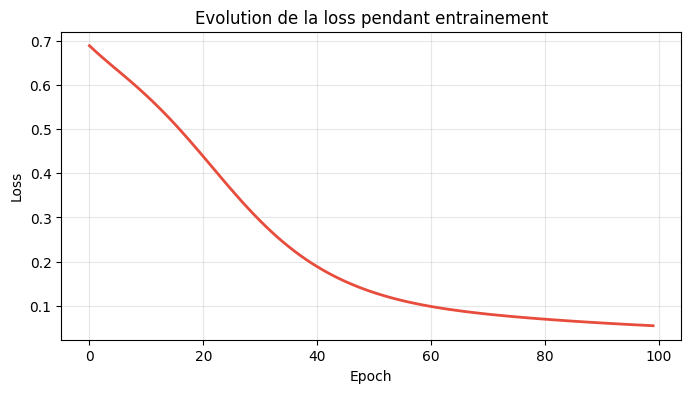

In [13]:
# Precision
model_nn.eval()
with torch.no_grad():
    out = model_nn(X_te)
    _, preds = torch.max(out, 1)
    pt_acc = (preds == y_te).sum().item() / len(y_te)
print(f'Precision PyTorch : {pt_acc:.2%}')

# Graphique de la loss
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
plt.plot(losses, color='#E74C3C', linewidth=2)
plt.title('Evolution de la loss pendant entrainement')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.show()


### Comparaison et Synthese

- **Comparaison de la precision :** Sur ce dataset, le modèle PyTorch (98.83%) a démontré une meilleure précision que le modèle Scikit-learn RandomForest (97.08%).
- **Comparaison des temps d'entrainement :** Le modèle PyTorch s'est entraîné beaucoup plus rapidement (0.586s) que le modèle Scikit-learn (4.466s pour 1000 arbres). Cela s'explique par le fait que PyTorch a utilisé le GPU, tandis que Scikit-learn a fonctionné uniquement sur le CPU.
- **Pour un dataset de 10 millions d'images :** PyTorch serait le choix privilégié. Sa capacité à exploiter les GPU permettrait un entraînement significativement plus rapide et plus efficace sur de grands datasets.
- **En production :** Pour garantir que le modèle fonctionnera identiquement en production, les conteneurs Docker sont une excellente solution pour garantir cette consistance.il est aussi préférable d'utiliser des formats de sérialisation de modèles,comme ONNX ou TorchScript pour PyTorch, ou joblib pour Scikit-learn et de s'assurer que l'environnement d'exécution (bibliothèques, versions, hardware) est cohérent entre le développement et la production.

## Pipeline complet pour mettre en production un modèle IA

1. **Préparer le matériel** : vérifier le GPU, la RAM, le stockage et le refroidissement pour s’assurer que la machine peut supporter l’entraînement et l’inférence.
2. **Installer l’OS et les pilotes** : configurer le système d’exploitation, les pilotes NVIDIA, CUDA et cuDNN afin que le GPU soit utilisable correctement.
3. **Développer et entraîner le modèle** : utiliser Python avec un framework adapté comme PyTorch ou Scikit-learn pour construire, tester et valider le modèle.
4. **Conteneuriser l’application** : créer une image Docker pour encapsuler le code, les dépendances et l’environnement d’exécution, afin d’obtenir un déploiement reproductible.
5. **Déployer dans le cloud** : publier le conteneur sur une VM, un serveur ou une plateforme cloud pour rendre le modèle accessible en production.
6. **Surveiller et maintenir** : mettre en place Prometheus, Grafana et Alertmanager pour suivre la température, l’utilisation GPU, la mémoire et déclencher des alertes en cas de problème.